Iris Flower Classification
Internship: Datheon — Machine Learning & Data Science

Objective: Build machine learning models to predict the species of an Iris flower using its measurements.

Models: Logistic Regression and Decision Tree

Evaluation: Accuracy, Precision, Recall, F1-score, and Confusion Matrix.

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Load the Iris dataset
iris = load_iris()

# Store the flower measurements in a table
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the flower species as a target column
df["species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

# Display the first five rows
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check the column names and data types
print("\nDataset information:")
df.info()

# Check the number of flowers in each species
print("\nSpecies distribution:")
print(df["species"].value_counts())


Dataset shape: (150, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [5]:

# Check whether any values are missing
print(df.isnull().sum())


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


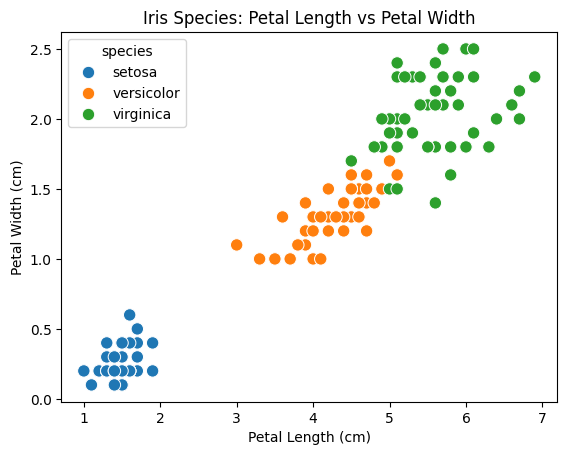

In [6]:

# Visualize petal length against petal width
sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    s=80
)

plt.title("Iris Species: Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.show()


In [7]:

# Features: the four flower measurements
X = df.drop("species", axis=1)

# Target: the flower species
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())


Features shape: (150, 4)
Target shape: (150,)

Feature columns:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [8]:

# Split data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 120
Testing samples: 30


In [9]:

# Create the scaler
scaler = StandardScaler()

# Learn scaling values from training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to testing data
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)


Original training shape: (120, 4)
Scaled training shape: (120, 4)
Scaled testing shape: (30, 4)


In [10]:

# Create the Logistic Regression model
logistic_model = LogisticRegression(max_iter=200)

# Train the model using the training data
logistic_model.fit(X_train_scaled, y_train)

# Predict the species of the test flowers
y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")
print("Predictions for the first 10 flowers:")
print(y_pred_logistic[:10])


Logistic Regression model trained successfully!
Predictions for the first 10 flowers:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [11]:

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(random_state=42)

# Train the model using the training data
tree_model.fit(X_train_scaled, y_train)

# Predict the species of the test flowers
y_pred_tree = tree_model.predict(X_test_scaled)

print("Decision Tree model trained successfully!")
print("Predictions for the first 10 flowers:")
print(y_pred_tree[:10])


Decision Tree model trained successfully!
Predictions for the first 10 flowers:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [12]:

# Function to evaluate a classification model
def evaluate_model(model_name, y_true, y_pred):
    print(f"\n{model_name}")
    print("-" * 40)

    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(
        precision_score(y_true, y_pred, average="weighted", zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(y_true, y_pred, average="weighted", zero_division=0), 4
    ))
    print("F1-score:", round(
        f1_score(y_true, y_pred, average="weighted", zero_division=0), 4
    ))

# Evaluate both trained models
evaluate_model("Logistic Regression", y_test, y_pred_logistic)
evaluate_model("Decision Tree", y_test, y_pred_tree)



Logistic Regression
----------------------------------------
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333

Decision Tree
----------------------------------------
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333


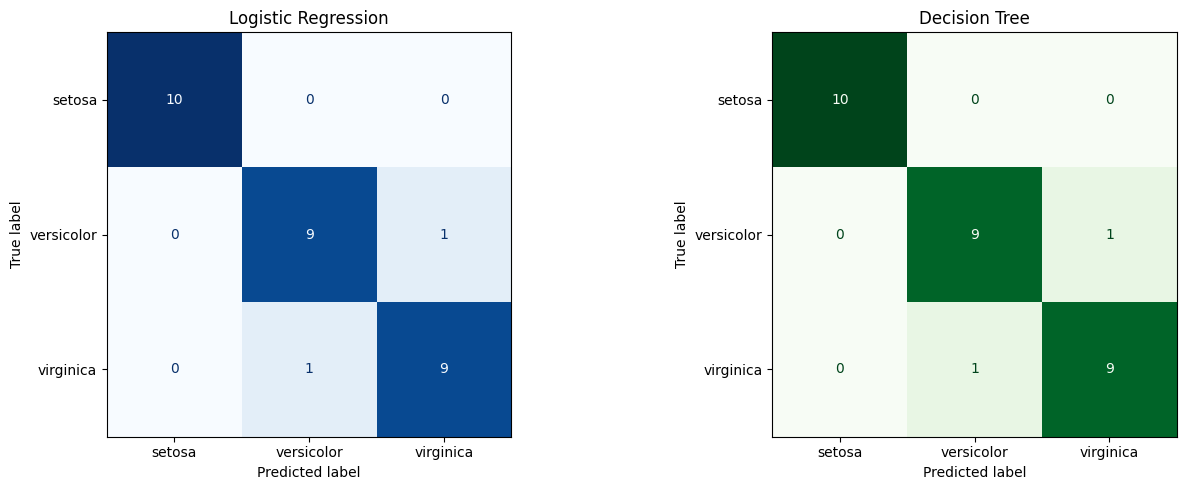

In [13]:

# Create confusion matrices
cm_logistic = confusion_matrix(
    y_test, y_pred_logistic, labels=iris.target_names
)

cm_tree = confusion_matrix(
    y_test, y_pred_tree, labels=iris.target_names
)

# Plot both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_logistic,
    display_labels=iris.target_names
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay(
    confusion_matrix=cm_tree,
    display_labels=iris.target_names
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Decision Tree")

plt.tight_layout()
plt.show()


In [14]:

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=iris.target_names,
    zero_division=0
))

print("DECISION TREE CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=iris.target_names,
    zero_division=0
))


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



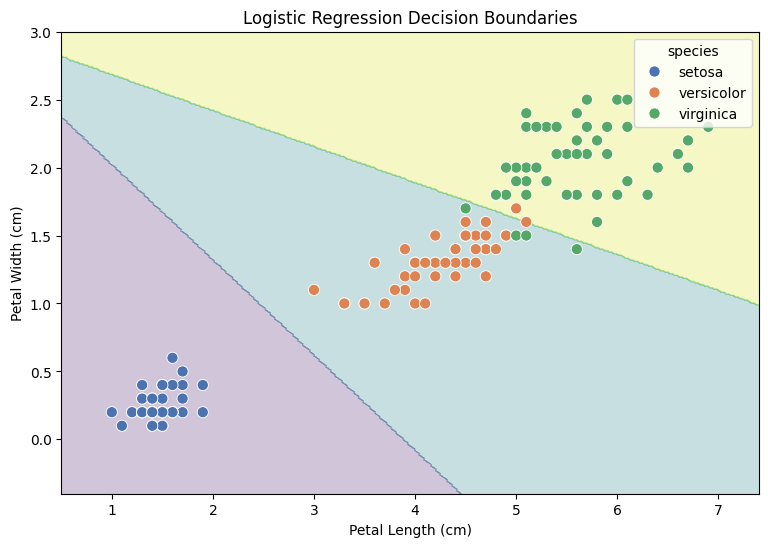

In [18]:

# Select the two petal measurements
X_2d = df[["petal length (cm)", "petal width (cm)"]]
y_num = iris.target

# Split the two-feature data
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_num,
    test_size=0.2,
    random_state=42,
    stratify=y_num
)

# Scale using training data only
scaler_2d = StandardScaler()
X2_train_scaled = scaler_2d.fit_transform(X2_train)

# Train a two-feature Logistic Regression model
boundary_model = LogisticRegression(max_iter=200)
boundary_model.fit(X2_train_scaled, y2_train)

# Create a grid covering the feature space
import numpy as np

x_min, x_max = X_2d.iloc[:, 0].min() - 0.5, X_2d.iloc[:, 0].max() + 0.5
y_min, y_max = X_2d.iloc[:, 1].min() - 0.5, X_2d.iloc[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_df = pd.DataFrame(
    grid,
    columns=X_2d.columns
)

grid_scaled = scaler_2d.transform(grid_df)
Z = boundary_model.predict(grid_scaled).reshape(xx.shape)

# Plot the decision regions and actual flowers
plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    palette="deep",
    s=65
)

plt.title("Logistic Regression Decision Boundaries")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.show()


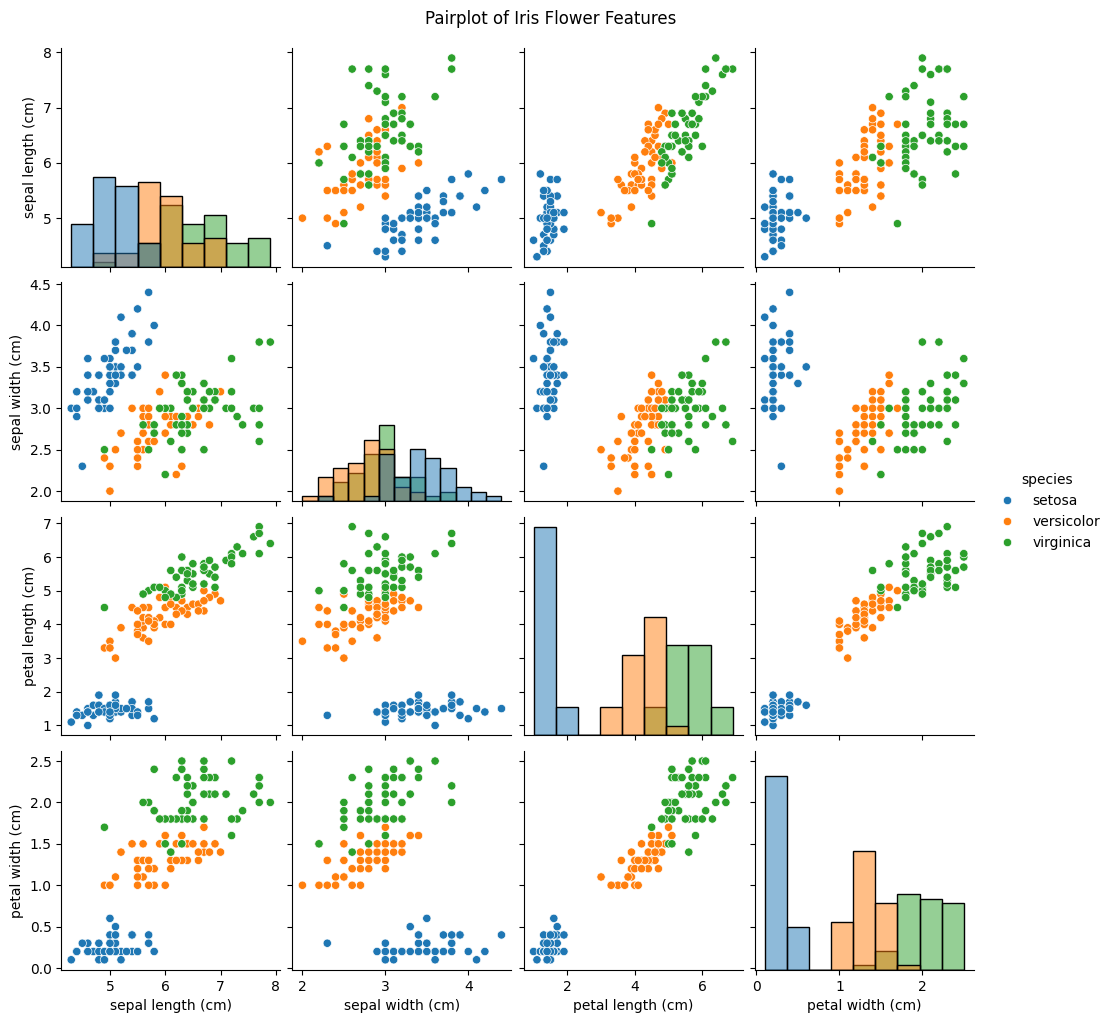

In [16]:

# Compare relationships between all four flower measurements
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Pairplot of Iris Flower Features", y=1.02)
plt.show()



## Results and Conclusion

The Iris dataset contains 150 samples, four numerical features, and three flower species. No missing values were found.

The dataset was split into 80% training data and 20% testing data. StandardScaler was used to scale the features, with the scaler fitted only on the training data.

Logistic Regression and Decision Tree classifiers were trained and evaluated using accuracy, precision, recall, F1-score, confusion matrices, and classification reports.

Both models achieved 93.33% accuracy on the test set. Both classified all Setosa samples correctly in this test split.

The scatterplot, pairplot, confusion matrices, and decision boundary visualization help us understand the data and model predictions.

Overall, both models performed well on this test set. Further testing would be needed to evaluate their performance on other unseen data.
